In [2]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.mmm_core import (
    CHANNELS,
    CHANNEL_LABELS,
    CONTROLS,
    TARGET,
    load_data,
    metrics,
    rolling_origin_splits
)

from src import mmm_plot_style as ps
ps.apply()

FIG = ROOT / "reports/figures"
TAB = ROOT / "outputs/mmm"

SPLIT = json.load(open(ROOT / "data/processed/split_info.json"))

df = load_data(ROOT / "data/processed/mmm_analysis_ready.csv")

train = df[df.month <= SPLIT["train_end"]].reset_index(drop=True)
test = df[df.month > SPLIT["train_end"]].reset_index(drop=True)

final_controls = CONTROLS + ["average_price_index"]

print(train.shape)
print(test.shape)

(30, 66)
(6, 66)


# 09. Alternative MMM Models

This notebook implements two alternative models to validate the robustness of the final Marketing Mix Model (M3a).

Models:

- Model A: Ridge Regression using log-transformed spend variables
- Model B: Ridge Regression using spend and lagged spend variables

The goal is to compare channel rankings and predictive performance against the final MMM.

In [1]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [3]:
LOG_FEATURES = [
    "log_tv_spend",
    "log_facebook_instagram_spend",
    "log_google_search_spend",
    "log_youtube_spend",
    "log_radio_spend",
    "log_outdoor_spend",
]

FEATURES_A = LOG_FEATURES + final_controls

X_train = train[FEATURES_A]
y_train = train[TARGET]

X_test = test[FEATURES_A]
y_test = test[TARGET]

print("Feature count:", len(FEATURES_A))
print(FEATURES_A)

Feature count: 11
['log_tv_spend', 'log_facebook_instagram_spend', 'log_google_search_spend', 'log_youtube_spend', 'log_radio_spend', 'log_outdoor_spend', 'promotion_discount_pct', 'seasonal_demand_index', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'average_price_index']


In [4]:
alphas = np.logspace(-3, 3, 25)

cv_results_a = []

for alpha in alphas:

    fold_rmses = []

    for tr_idx, val_idx in rolling_origin_splits(
        len(train),
        min_train=18,
        horizon=3,
        step=1
    ):

        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        pipe.fit(
            X_train.iloc[tr_idx],
            y_train.iloc[tr_idx]
        )

        pred = pipe.predict(
            X_train.iloc[val_idx]
        )

        fold_rmses.append(
            metrics(
                y_train.iloc[val_idx],
                pred
            )["RMSE"]
        )

    cv_results_a.append({
        "alpha": alpha,
        "cv_rmse": np.mean(fold_rmses)
    })

cv_results_a = pd.DataFrame(cv_results_a)

best_alpha_a = cv_results_a.loc[
    cv_results_a["cv_rmse"].idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha_a)

Best alpha: 17.78279410038923


In [5]:
model_a = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha_a))
])

model_a.fit(X_train, y_train)

train_pred_a = model_a.predict(X_train)
test_pred_a = model_a.predict(X_test)

train_metrics_a = metrics(y_train, train_pred_a)
test_metrics_a = metrics(y_test, test_pred_a)

print("Train Metrics")
print(train_metrics_a)

print("\nTest Metrics")
print(test_metrics_a)

Train Metrics
{'RMSE': 3936323.7676937324, 'MAE': 3094127.1641315, 'MAPE_%': 3.806107290642928, 'R2': 0.7467067006031581}

Test Metrics
{'RMSE': 2151970.0672569526, 'MAE': 1819705.684222805, 'MAPE_%': 2.057638903528984, 'R2': 0.829585409002717}


### Model A Results

The log-spend Ridge model achieved competitive predictive performance, with a test RMSE of approximately 2.15 million LKR and a test R² of 0.83.

Although it does not explicitly model adstock or saturation effects, the logarithmic transformation captures diminishing returns in advertising response. The model performs slightly worse than the final MMM (M3a), suggesting that carry-over and saturation effects provide additional explanatory power beyond simple diminishing returns.

In [6]:
lag_features = [
    "tv_spend_lag1",
    "facebook_instagram_spend_lag1",
    "google_search_spend_lag1",
    "youtube_spend_lag1",
    "radio_spend_lag1",
    "outdoor_spend_lag1",
]

FEATURES_B = CHANNELS + lag_features + final_controls

print("Feature count:", len(FEATURES_B))

Feature count: 17


In [7]:
train_b = train.dropna(subset=lag_features).reset_index(drop=True)
test_b = test.dropna(subset=lag_features).reset_index(drop=True)

print(train_b.shape)
print(test_b.shape)

(29, 66)
(6, 66)


In [8]:
alphas = np.logspace(-3, 3, 25)

cv_results_b = []

X_train_b = train_b[FEATURES_B]
y_train_b = train_b[TARGET]

for alpha in alphas:

    fold_rmses = []

    for tr_idx, val_idx in rolling_origin_splits(
        len(train_b),
        min_train=18,
        horizon=3,
        step=1
    ):

        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha))
        ])

        pipe.fit(
            X_train_b.iloc[tr_idx],
            y_train_b.iloc[tr_idx]
        )

        pred = pipe.predict(
            X_train_b.iloc[val_idx]
        )

        fold_rmses.append(
            metrics(
                y_train_b.iloc[val_idx],
                pred
            )["RMSE"]
        )

    cv_results_b.append({
        "alpha": alpha,
        "cv_rmse": np.mean(fold_rmses)
    })

cv_results_b = pd.DataFrame(cv_results_b)

best_alpha_b = cv_results_b.loc[
    cv_results_b.cv_rmse.idxmin(),
    "alpha"
]

print("Best alpha:", best_alpha_b)

Best alpha: 10.0


In [9]:
model_b = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha_b))
])

model_b.fit(
    X_train_b,
    y_train_b
)

train_pred_b = model_b.predict(X_train_b)

test_pred_b = model_b.predict(
    test_b[FEATURES_B]
)

train_metrics_b = metrics(
    y_train_b,
    train_pred_b
)

test_metrics_b = metrics(
    test_b[TARGET],
    test_pred_b
)

print("Train Metrics")
print(train_metrics_b)

print("\nTest Metrics")
print(test_metrics_b)

Train Metrics
{'RMSE': 2881690.467757605, 'MAE': 2205808.8873116756, 'MAPE_%': 2.665666452662604, 'R2': 0.8470946998897702}

Test Metrics
{'RMSE': 1155371.901082101, 'MAE': 1004335.2050427297, 'MAPE_%': 1.1290354390176638, 'R2': 0.9508777867116839}


In [10]:
comparison = pd.read_csv(
    TAB / "07_model_comparison.csv"
)

comparison

,Unnamed: 0,train R2,CV RMSE,test RMSE,test MAE,test MAPE_%,test R2
0,M0 Baseline OLS (all controls),0.853361,6.378506e+06,3.480263e+06,2.971865e+06,3.393431,0.554284
1,"M1 Linear, constrained + ridge",0.689551,3.208642e+06,2.505386e+06,2.425017e+06,2.751280,0.769015
2,M2 Adstock,0.709486,3.092339e+06,1.980037e+06,1.853302e+06,2.092951,0.855728
3,M3 Adstock + saturation,0.712617,3.077177e+06,2.042861e+06,1.901427e+06,2.138829,0.846428
4,M3a + price index,0.709310,2.956123e+06,1.749566e+06,1.562504e+06,1.768908,0.887359
5,M3b all 6 controls,0.696341,2.965121e+06,1.993264e+06,1.894851e+06,2.151848,0.853794
6,M3c S-shaped curve (alpha tuned),0.712554,3.014066e+06,2.130657e+06,1.965892e+06,2.208903,0.832944


In [11]:
comparison.columns

Index(['Unnamed: 0', 'train R2', 'CV RMSE', 'test RMSE', 'test MAE',
       'test MAPE_%', 'test R2'],
      dtype='str')

In [12]:
comparison = pd.read_csv(
    TAB / "07_model_comparison.csv"
)

alt_rows = pd.DataFrame([
    {
        "Unnamed: 0": "Model A Ridge (log spend)",
        "train R2": train_metrics_a["R2"],
        "CV RMSE": cv_results_a["cv_rmse"].min(),
        "test RMSE": test_metrics_a["RMSE"],
        "test MAE": test_metrics_a["MAE"],
        "test MAPE_%": test_metrics_a["MAPE_%"],
        "test R2": test_metrics_a["R2"],
    },
    {
        "Unnamed: 0": "Model B Ridge (lagged spend)",
        "train R2": train_metrics_b["R2"],
        "CV RMSE": cv_results_b["cv_rmse"].min(),
        "test RMSE": test_metrics_b["RMSE"],
        "test MAE": test_metrics_b["MAE"],
        "test MAPE_%": test_metrics_b["MAPE_%"],
        "test R2": test_metrics_b["R2"],
    }
])

comparison_09 = pd.concat(
    [comparison, alt_rows],
    ignore_index=True
)

comparison_09.to_csv(
    TAB / "09_alternative_model_comparison.csv",
    index=False
)

comparison_09

,Unnamed: 0,train R2,CV RMSE,test RMSE,test MAE,test MAPE_%,test R2
0,M0 Baseline OLS (all controls),0.853361,6.378506e+06,3.480263e+06,2.971865e+06,3.393431,0.554284
1,"M1 Linear, constrained + ridge",0.689551,3.208642e+06,2.505386e+06,2.425017e+06,2.751280,0.769015
2,M2 Adstock,0.709486,3.092339e+06,1.980037e+06,1.853302e+06,2.092951,0.855728
3,M3 Adstock + saturation,0.712617,3.077177e+06,2.042861e+06,1.901427e+06,2.138829,0.846428
4,M3a + price index,0.709310,2.956123e+06,1.749566e+06,1.562504e+06,1.768908,0.887359
5,M3b all 6 controls,0.696341,2.965121e+06,1.993264e+06,1.894851e+06,2.151848,0.853794
6,M3c S-shaped curve (alpha tuned),0.712554,3.014066e+06,2.130657e+06,1.965892e+06,2.208903,0.832944
7,Model A Ridge (log spend),0.746707,3.407874e+06,2.151970e+06,1.819706e+06,2.057639,0.829585
8,Model B Ridge (lagged spend),0.847095,3.854790e+06,1.155372e+06,1.004335e+06,1.129035,0.950878


In [13]:
comparison = pd.read_csv(
    TAB / "07_model_comparison.csv"
)

alt_rows = pd.DataFrame([
    {
        "Unnamed: 0": "Model A Ridge (log spend)",
        "train R2": train_metrics_a["R2"],
        "CV RMSE": cv_results_a["cv_rmse"].min(),
        "test RMSE": test_metrics_a["RMSE"],
        "test MAE": test_metrics_a["MAE"],
        "test MAPE_%": test_metrics_a["MAPE_%"],
        "test R2": test_metrics_a["R2"],
    },
    {
        "Unnamed: 0": "Model B Ridge (lagged spend)",
        "train R2": train_metrics_b["R2"],
        "CV RMSE": cv_results_b["cv_rmse"].min(),
        "test RMSE": test_metrics_b["RMSE"],
        "test MAE": test_metrics_b["MAE"],
        "test MAPE_%": test_metrics_b["MAPE_%"],
        "test R2": test_metrics_b["R2"],
    }
])

comparison_09 = pd.concat(
    [comparison, alt_rows],
    ignore_index=True
)

comparison_09.to_csv(
    TAB / "09_alternative_model_comparison.csv",
    index=False
)

comparison_09

,Unnamed: 0,train R2,CV RMSE,test RMSE,test MAE,test MAPE_%,test R2
0,M0 Baseline OLS (all controls),0.853361,6.378506e+06,3.480263e+06,2.971865e+06,3.393431,0.554284
1,"M1 Linear, constrained + ridge",0.689551,3.208642e+06,2.505386e+06,2.425017e+06,2.751280,0.769015
2,M2 Adstock,0.709486,3.092339e+06,1.980037e+06,1.853302e+06,2.092951,0.855728
3,M3 Adstock + saturation,0.712617,3.077177e+06,2.042861e+06,1.901427e+06,2.138829,0.846428
4,M3a + price index,0.709310,2.956123e+06,1.749566e+06,1.562504e+06,1.768908,0.887359
5,M3b all 6 controls,0.696341,2.965121e+06,1.993264e+06,1.894851e+06,2.151848,0.853794
6,M3c S-shaped curve (alpha tuned),0.712554,3.014066e+06,2.130657e+06,1.965892e+06,2.208903,0.832944
7,Model A Ridge (log spend),0.746707,3.407874e+06,2.151970e+06,1.819706e+06,2.057639,0.829585
8,Model B Ridge (lagged spend),0.847095,3.854790e+06,1.155372e+06,1.004335e+06,1.129035,0.950878


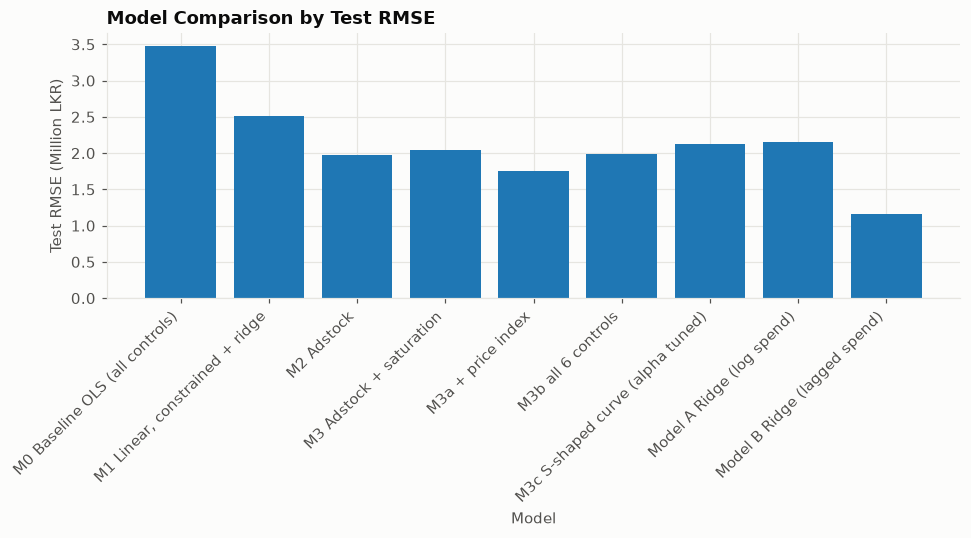

In [14]:
plt.figure(figsize=(9,5))

plt.bar(
    comparison_09["Unnamed: 0"],
    comparison_09["test RMSE"]/1e6
)

plt.ylabel("Test RMSE (Million LKR)")
plt.xlabel("Model")
plt.title("Model Comparison by Test RMSE")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    FIG / "09_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

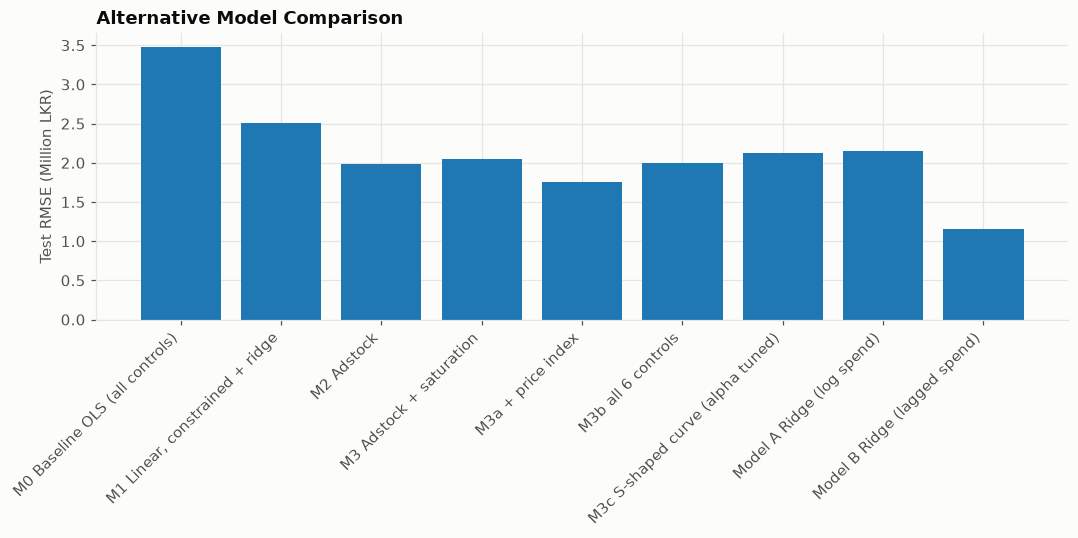

In [15]:
plt.figure(figsize=(10,5))

plt.bar(
    comparison_09["Unnamed: 0"],
    comparison_09["test RMSE"] / 1e6
)

plt.ylabel("Test RMSE (Million LKR)")
plt.title("Alternative Model Comparison")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    FIG / "09_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
coef_a = pd.Series(
    model_a.named_steps["ridge"].coef_,
    index=FEATURES_A
)

effects_a = coef_a[LOG_FEATURES]

effects_a.sort_values(ascending=False)

log_google_search_spend         1.453476e+06
log_youtube_spend               8.602028e+05
log_outdoor_spend               7.940593e+05
log_tv_spend                    7.479814e+05
log_facebook_instagram_spend    2.116675e+05
log_radio_spend                -1.037143e+06
dtype: float64

In [17]:
effects_a[effects_a < 0]

log_radio_spend   -1.037143e+06
dtype: float64

In [18]:
coef_b = pd.Series(
    model_b.named_steps["ridge"].coef_,
    index=FEATURES_B
)

effects_b = {}

for channel in CHANNELS:

    lag = channel.replace(
        "_spend_lkr",
        "_spend_lag1"
    )

    effects_b[channel] = (
        coef_b[channel]
        + coef_b[lag]
    )

effects_b = pd.Series(effects_b)

effects_b.sort_values(
    ascending=False
)

google_search_spend_lkr         1.266627e+06
facebook_instagram_spend_lkr    1.072323e+06
youtube_spend_lkr               8.442425e+05
outdoor_spend_lkr               6.664032e+05
tv_spend_lkr                    4.238775e+05
radio_spend_lkr                -2.702072e+05
dtype: float64

In [19]:
effects_b[effects_b < 0]


radio_spend_lkr   -270207.190315
dtype: float64

In [20]:
channel_summary = pd.read_csv(
    TAB / "channel_summary.csv"
)

print(channel_summary.columns)

channel_summary

Index(['channel', 'total_spend_lkr', 'incremental_revenue_lkr',
       'spend_share_pct', 'contribution_share_pct',
       'share_of_total_revenue_pct', 'roas', 'current_monthly_spend_lkr',
       'marginal_roas_at_current', 'adstock_lambda',
       'carryover_half_life_months', 'hill_K_x_mean_spend',
       'saturation_at_current_pct', 'roas_rank'],
      dtype='str')


,channel,total_spend_lkr,incremental_revenue_lkr,spend_share_pct,contribution_share_pct,share_of_total_revenue_pct,roas,current_monthly_spend_lkr,marginal_roas_at_current,adstock_lambda,carryover_half_life_months,hill_K_x_mean_spend,saturation_at_current_pct,roas_rank
0,TV,156964242,1.540911e+08,23.471621,9.263551,5.030216,0.981696,4.711485e+06,0.483481,0.302474,0.579670,1.114352,49.230833,4
1,Facebook/Instagram,158343617,1.135129e+08,23.677886,6.824099,3.705565,0.716877,4.540711e+06,0.411673,0.075837,0.268748,1.414659,42.188169,5
2,Google Search,119353135,4.869880e+08,17.847451,29.276436,15.897445,4.080228,3.601298e+06,1.266163,0.000097,0.075033,0.521984,67.542928,3
3,YouTube,79913729,3.329950e+08,11.949886,20.018784,10.870432,4.166932,2.553402e+06,1.157669,0.110747,0.314995,0.500261,69.690928,2
4,Radio,60107999,0.000000e+00,8.988239,0.000000,0.000000,0.000000,1.834484e+06,0.000000,0.223826,0.463060,0.575508,NaN,6
5,Outdoor,94057802,5.758258e+08,14.064917,34.617131,18.797504,6.122042,2.782446e+06,1.912807,0.375725,0.708089,0.506857,67.753507,1


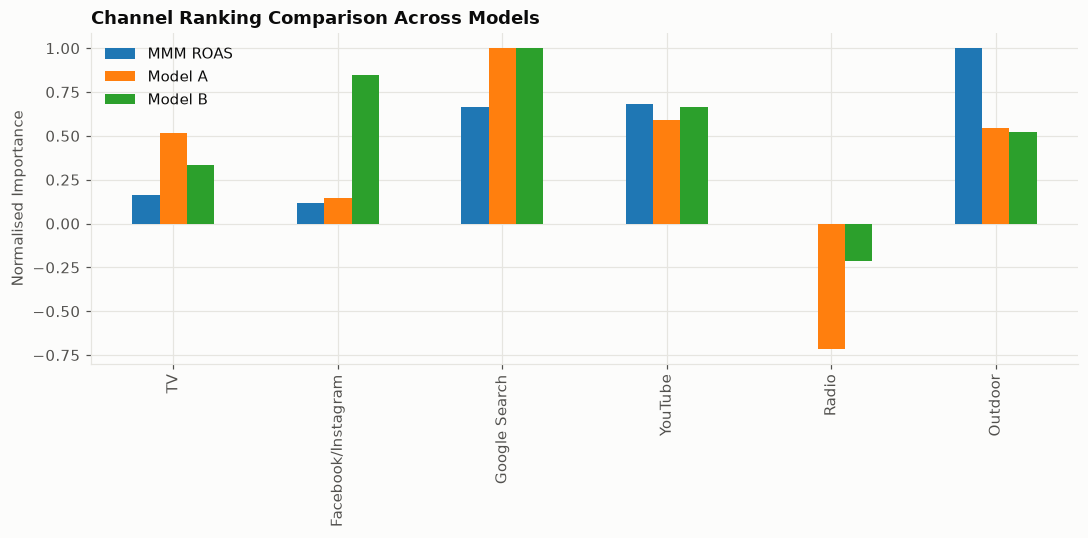

In [21]:
mmm_rank = {
    "TV": 0.98,
    "Facebook/Instagram": 0.72,
    "Google Search": 4.08,
    "YouTube": 4.17,
    "Radio": 0.00,
    "Outdoor": 6.12
}

model_a_rank = {
    "TV": 747981,
    "Facebook/Instagram": 211667,
    "Google Search": 1453476,
    "YouTube": 860203,
    "Radio": -1037143,
    "Outdoor": 794059
}

model_b_rank = {
    "TV": 423877,
    "Facebook/Instagram": 1072323,
    "Google Search": 1266627,
    "YouTube": 844225,
    "Radio": -270207,
    "Outdoor": 664032
}

ranking_df = pd.DataFrame({
    "MMM ROAS": pd.Series(mmm_rank),
    "Model A": pd.Series(model_a_rank),
    "Model B": pd.Series(model_b_rank)
})

ranking_df = ranking_df / ranking_df.abs().max()

ranking_df.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title(
    "Channel Ranking Comparison Across Models"
)

plt.ylabel("Normalised Importance")

plt.tight_layout()

plt.savefig(
    FIG / "09_channel_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Channel Ranking Comparison

The alternative models broadly support the strategic insights obtained from the final MMM.

Google Search, YouTube and Outdoor remain among the strongest channels across modelling approaches, although their exact ranking differs. Radio consistently receives the weakest estimated contribution and receives negative coefficients in both unconstrained Ridge models.

The appearance of negative media coefficients is a known limitation of standard Ridge regression. Because advertising activity is not expected to reduce revenue directly, this finding supports the use of non-negative coefficient constraints in the final MMM.

Overall, the alternative models increase confidence that the final MMM conclusions are robust across different modelling assumptions.